In [ ]:
from google.colab import files

In [ ]:
uploaded=files.upload()

In [ ]:
#importing library

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
# reading  the csv file
df=pd.read_csv("netflix_customer_churn-selected-columns.csv")

In [ ]:
df.head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1


0 represent the active customer and 1 represent the churned customer

In [ ]:
df.shape

(5000, 10)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        5000 non-null   object 
 1   age                5000 non-null   int64  
 2   gender             5000 non-null   object 
 3   subscription_type  5000 non-null   object 
 4   watch_hours        5000 non-null   float64
 5   last_login_days    5000 non-null   int64  
 6   region             5000 non-null   object 
 7   device             5000 non-null   object 
 8   monthly_fee        5000 non-null   float64
 9   churned            5000 non-null   int64  
dtypes: float64(2), int64(3), object(5)
memory usage: 390.8+ KB


In [ ]:
#checking null value
#the data does not contains null value
df.isnull().sum()

,0
customer_id,0
age,0
gender,0
subscription_type,0
watch_hours,0
last_login_days,0
region,0
device,0
monthly_fee,0
churned,0


In [ ]:
#there is no duplicates
df.duplicated().sum()

np.int64(0)

# Data cleaning

In [ ]:
df.head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1


In [ ]:
df_copy=df.copy()

In [ ]:
df_copy.dtypes

,0
customer_id,object
age,int64
gender,object
subscription_type,object
watch_hours,float64
last_login_days,int64
region,object
device,object
monthly_fee,float64
churned,int64


In [ ]:
df_copy['gender'].unique()

array(['Other', 'Female', 'Male'], dtype=object)

In [ ]:
df_copy['subscription_type'].unique()

array(['Basic', 'Standard', 'Premium'], dtype=object)

In [ ]:
df_copy['last_login_days'].unique()

array([29, 19, 10, 12, 13, 26, 20, 56, 34, 36, 38, 23, 33,  7, 32, 40, 27,
        4, 57, 43, 18,  6, 55, 53, 52,  0, 48, 16, 35, 45,  1, 15, 14, 25,
       50, 44, 39, 24, 21, 22, 11, 30, 37, 31, 46, 41,  2,  3, 51,  9, 54,
       17, 49, 42, 28, 59, 58, 60, 47,  5,  8])

In [ ]:
df_copy['region'].unique()

array(['Africa', 'Europe', 'Asia', 'Oceania', 'South America',
       'North America'], dtype=object)

In [ ]:
df_copy['device'].unique()

array(['TV', 'Mobile', 'Laptop', 'Desktop', 'Tablet'], dtype=object)

In [ ]:
df_copy['monthly_fee'].unique()

array([ 8.99, 13.99, 17.99])

In [ ]:
df_copy['churned'].unique()

array([1, 0])

In [ ]:
status={1:"churned",0:"Active"}
df_copy["churned_status"]=df_copy['churned'].map(status)

In [ ]:
df_copy.describe()

,age,watch_hours,last_login_days,monthly_fee,churned
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,43.847400,11.649450,30.089800,13.683400,0.503000
std,15.501128,12.014654,17.536078,3.692062,0.500041
min,18.000000,0.010000,0.000000,8.990000,0.000000
25%,30.000000,3.337500,15.000000,8.990000,0.000000
50%,44.000000,8.000000,30.000000,13.990000,1.000000
75%,58.000000,16.030000,45.000000,17.990000,1.000000
max,70.000000,110.400000,60.000000,17.990000,1.000000


In [ ]:
df_copy.select_dtypes(include=np.number).columns

Index(['age', 'watch_hours', 'last_login_days', 'monthly_fee', 'churned'], dtype='object')

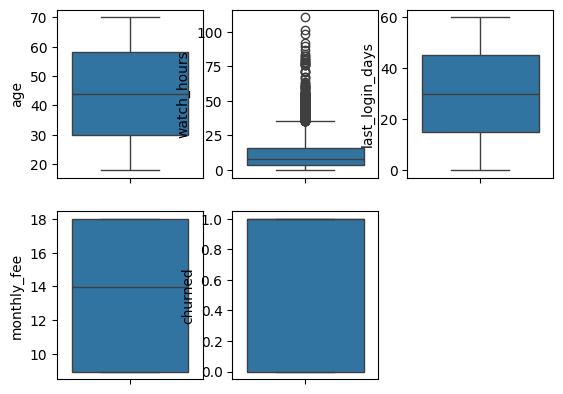

In [ ]:
#checking the outliers
numeric_number=['age', 'watch_hours', 'last_login_days', 'monthly_fee', 'churned']
for i,cols in enumerate(numeric_number,start=1):
  plt.subplot(2,3,i)
  sns.boxplot(df_copy[cols])

In [ ]:
#checking outliers
for cols in numeric_number:
 IQR=df_copy[cols].quantile(0.75)-df_copy[cols].quantile(0.25)
 lowerfence=df_copy[cols].quantile(0.25)-1.5*IQR
 highfence=df_copy[cols].quantile(0.75)+1.5*IQR
 print(f"lower_fence {cols}: {lowerfence}")
 print(f"high_fence {cols}: {highfence}")


lower_fence age: -12.0
high_fence age: 100.0
lower_fence watch_hours: -15.70125
high_fence watch_hours: 35.06875
lower_fence last_login_days: -30.0
high_fence last_login_days: 90.0
lower_fence monthly_fee: -4.509999999999996
high_fence monthly_fee: 31.489999999999995
lower_fence churned: -1.5
high_fence churned: 2.5


In [ ]:
df_copy.head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,churned_status
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,churned
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,churned
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Active
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,churned
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,churned


In [ ]:
df[numeric_number].quantile(0.25)

,0.25
age,30.0000
watch_hours,3.3375
last_login_days,15.0000
monthly_fee,8.9900
churned,0.0000


#EDA exploratory

In [ ]:
df_copy["gender"].value_counts()

,count
gender,
Female,1711
Male,1654
Other,1635


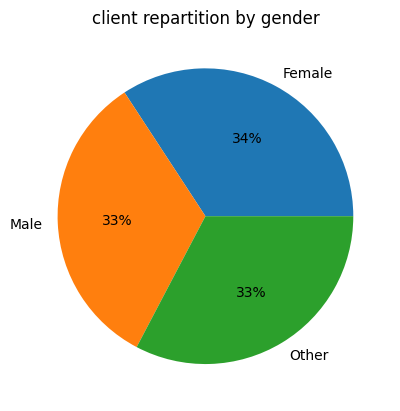

In [ ]:
#total client by gender
plt.pie(df_copy["gender"].value_counts(),labels=df_copy["gender"].value_counts().index,autopct="%1.0f%%")
plt.title("client repartition by gender")
plt.show()

* 33% percent of the client are famales
* 34% of the client are males
* 33% of the client gender are not precise or maybe an other gender group

-- we notice that there are as many females as males


In [ ]:
df_copy.head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,churned_status
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,churned
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,churned
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Active
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,churned
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,churned


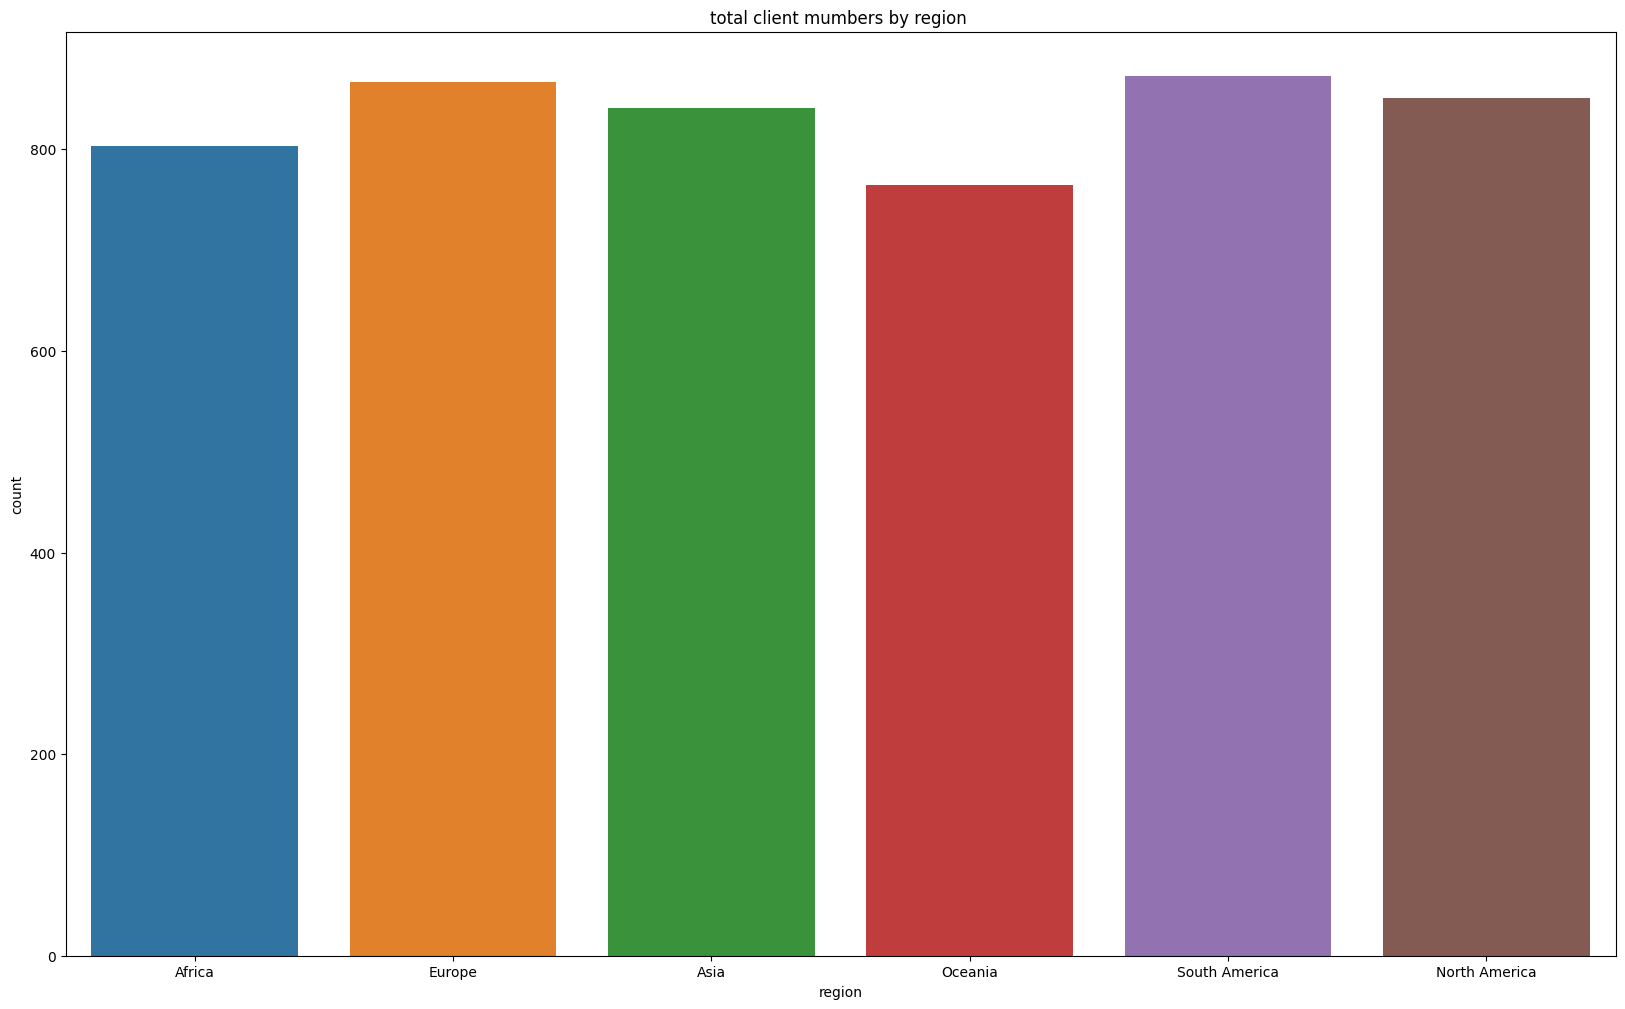

In [ ]:
plt.rcParams["figure.figsize"]=(20,12)
sns.countplot(df_copy,x="region",hue="region")
plt.title("total client mumbers by region ")
plt.show()


In [ ]:
#calculating the percentage of client  by region based on the totale client
members_percentage_by_region=(df_copy.groupby("region")["region"].count()/df_copy["region"].count())*100
members_percentage_by_region=members_percentage_by_region.reset_index(name="percentage").sort_values("percentage",ascending=False)

In [ ]:
members_percentage_by_region

,region,percentage
5,South America,17.46
2,Europe,17.34
3,North America,17.02
1,Asia,16.82
0,Africa,16.06
4,Oceania,15.30


# percentage of netflix client by region
* South America is top region watching netflix the most based on the dataset **17.34%**
* followed by Europe with **17.34%**, North America with **17.02%**, Asia with **16.82%**, Africa with **16.06%**
and finally by Oceania with **15.30%** which is the bottom region

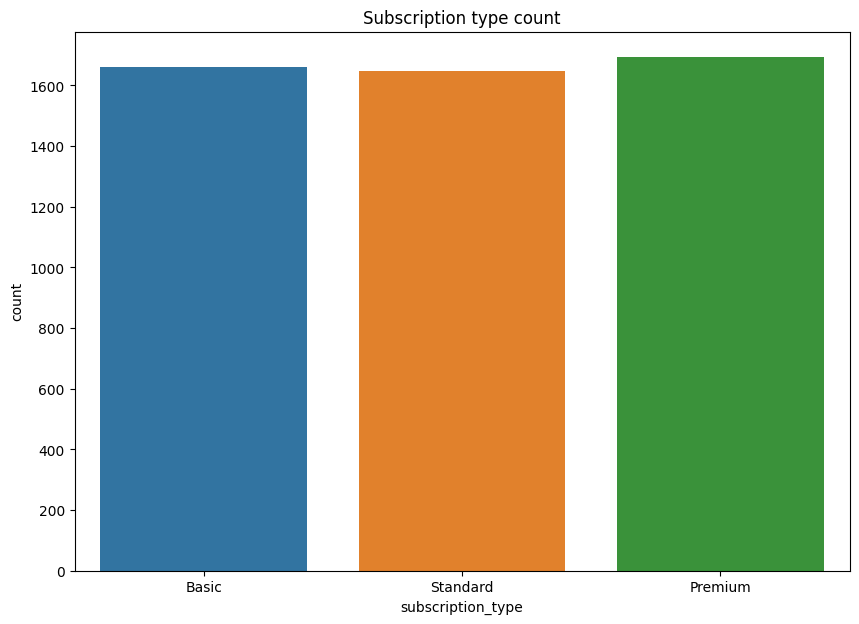

In [ ]:
# visulalizing the subscription type on a seaborn countplot
plt.figure(figsize=(10,7))
sns.countplot(df_copy,x="subscription_type",hue="subscription_type")
plt.title("Subscription type count")
plt.show()

base on the visualization we notice that there are as many premium as basic and standard

In [ ]:
#let check which one of the subscription type is dominating the market
subscription_type_by_percentage=df_copy.groupby("subscription_type")["subscription_type"].count()*100/df_copy['subscription_type'].value_counts()
subscription_type_by_percentage.reset_index(name="percentage").sort_values("percentage",ascending=True)
subscription_type_by_percentage

,0
subscription_type,
Basic,100.0
Premium,100.0
Standard,100.0


In [ ]:
#visuaisationg

In [ ]:
df_copy.head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,churned_status
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,churned
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,churned
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Active
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,churned
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,churned


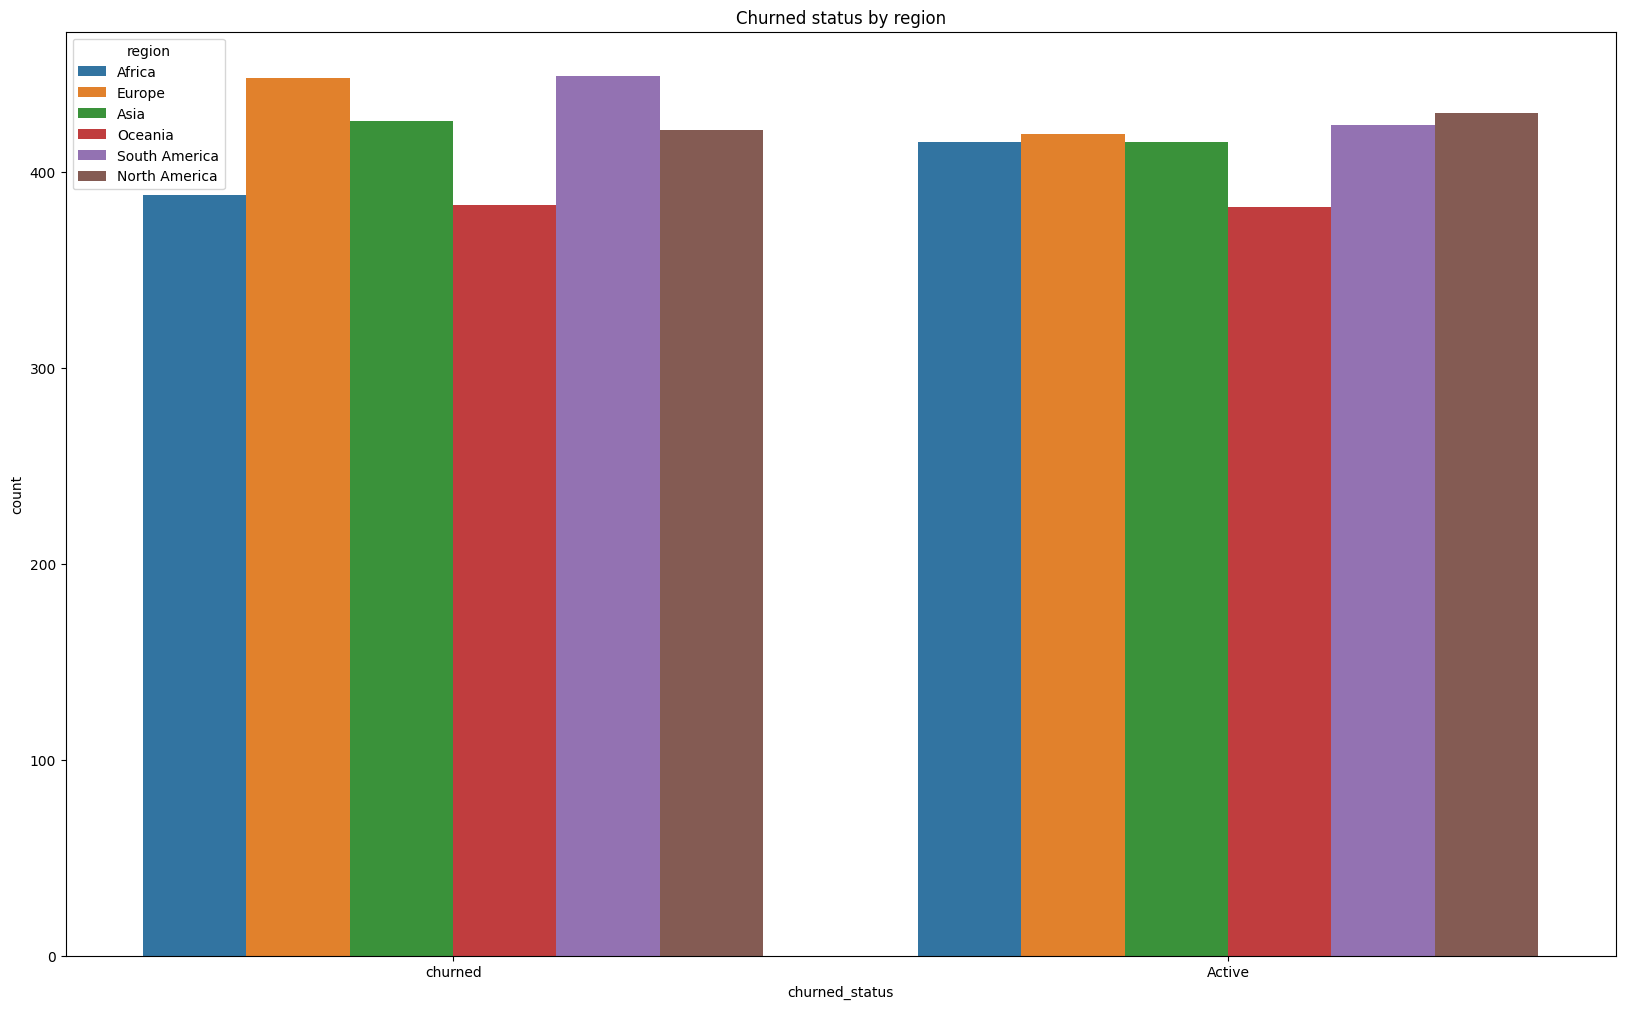

In [ ]:
#visualing the churned ststus by region
sns.countplot(df_copy,x="churned_status",hue="region")
plt.title("Churned status by region")
plt.show()

In [ ]:
# checking the most active country
churned_tatus_by_perct=df_copy.groupby(["churned_status","region"])["region"].count()*100/df_copy.groupby(["churned_status"])["region"].count()
churned_tatus_by_perct.reset_index(name="percentage").sort_values(["churned_status","percentage"],ascending=False)

,churned_status,region,percentage
11,churned,South America,17.852883
8,churned,Europe,17.813121
7,churned,Asia,16.938370
9,churned,North America,16.739563
6,churned,Africa,15.427435
10,churned,Oceania,15.228628
3,Active,North America,17.303823
5,Active,South America,17.062374
2,Active,Europe,16.861167
0,Active,Africa,16.700201


# churned region
* most of the client churned come from South America with **17.85%**
* followed by Europe with **17.81%**,Asia with**16.93%**,North America with **16.73%**, Africa with **15.42%** and finally Ocenia with **15.22%**

# Active region

* most of the active client come from North America with **17.30%**
* followed by with South America with **17.06%**, Europe with **16.86%**,Africa with **16.70%** Same with Asia ,and  Ocenia with 15.37%


In [ ]:
# subscription type impact in churned client
churned_tatus_by_perct_s=df_copy.groupby(["churned_status","subscription_type"])["subscription_type"].count()*100/df_copy.groupby(["churned_status"])["subscription_type"].count()
churned_tatus_by_perct_s.reset_index(name="percentage").sort_values(["churned_status","percentage"],ascending=False)

,churned_status,subscription_type,percentage
3,churned,Basic,40.834990
5,churned,Standard,29.741551
4,churned,Premium,29.423459
1,Active,Premium,38.350101
2,Active,Standard,36.136821
0,Active,Basic,25.513078


# churned
* **40.83%** of churned were basic
* **29.74%** of churned client were standard
* **29.42%** of churned client were premium

# churned
* **38.35%** of active client are premium
* **36.13%** of active client are standard
* **25.51%** of active client are premium


# Feature engeneering

In [ ]:
## creating independent and dependent feature
X=df_copy[['age', 'gender', 'subscription_type', 'watch_hours',
       'last_login_days', 'region', 'device', 'monthly_fee']]
y=df_copy['churned']

In [ ]:
# spliting the dataset in train and test
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(X,y,train_size=0.70,random_state=42)


In [ ]:
# numeric columns and cataegory columns
numeric_cols=x_train.select_dtypes(include=np.number).columns.tolist()
categoric_cols=x_train.select_dtypes("object").columns.tolist()

In [ ]:
#caling numerical value
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

In [ ]:
x_train[numeric_cols]=scaler.fit_transform(x_train[numeric_cols])
x_test[numeric_cols]=scaler.transform(x_test[numeric_cols])

In [ ]:
from sklearn.compose import ColumnTransformer

In [ ]:
# encoding categorical value
from sklearn.preprocessing import OneHotEncoder


In [ ]:
encoder=OneHotEncoder(sparse_output=False,handle_unknown="ignore")
encoder.fit_transform(x_train[categoric_cols])
encoded_cols=encoder.get_feature_names_out(categoric_cols).tolist()
x_train[encoded_cols]=encoder.fit_transform(x_train[categoric_cols])
x_test[encoded_cols]=encoder.transform(x_test[categoric_cols])



In [ ]:
x_train=x_train[numeric_cols + encoded_cols]
x_test=x_test[numeric_cols+ encoded_cols]

In [ ]:
x_train

,age,watch_hours,last_login_days,monthly_fee,gender_Female,gender_Male,gender_Other,subscription_type_Basic,subscription_type_Premium,subscription_type_Standard,...,region_Asia,region_Europe,region_North America,region_Oceania,region_South America,device_Desktop,device_Laptop,device_Mobile,device_TV,device_Tablet
1840,1.102553,-0.365048,-1.097236,0.085527,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2115,0.326589,0.448598,-0.811557,-1.260446,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4437,0.261925,0.946613,1.359603,1.162305,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1146,0.326589,-0.695670,1.645282,1.162305,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2486,-1.290003,-0.889713,0.902517,1.162305,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4426,-0.190721,-0.871391,1.073924,0.085527,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
466,-0.772694,1.099849,0.616838,1.162305,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3092,-1.677985,-0.676516,0.845381,0.085527,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3772,0.391252,-0.308418,1.188196,1.162305,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


In [ ]:
##feauture prediction
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

In [ ]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
params = {
    "penalty": ["l1", "l2", "elasticnet", None],
    "solver": ["lbfgs", "liblinear", "newton-cg", "newton-cholesky", "sag", "saga"]
}

In [ ]:
Lg=LogisticRegression()
grid=GridSearchCV(Lg,params,cv=4)

In [ ]:
grid.fit(x_train,y_train)

GridSearchCV(cv=4, estimator=LogisticRegression(),
             param_grid={'penalty': ['l1', 'l2', 'elasticnet', None],
                         'solver': ['lbfgs', 'liblinear', 'newton-cg',
                                    'newton-cholesky', 'sag', 'saga']})

In [ ]:
y_preds=grid.predict(x_test)

In [ ]:
# checking the machine learning metrics
from sklearn.metrics import classification_report,accuracy_score

In [ ]:
print(accuracy_score(y_test,y_preds))
print(classification_report(y_test,y_preds))

0.8653333333333333
              precision    recall  f1-score   support

           0       0.87      0.86      0.87       753
           1       0.86      0.87      0.87       747

    accuracy                           0.87      1500
   macro avg       0.87      0.87      0.87      1500
weighted avg       0.87      0.87      0.87      1500



In [ ]:
from sklearn.svm import SVC

In [ ]:
params2={"kernel":['linear', 'poly', 'rbf', 'sigmoid'],
        "gamma":["scale","auto"]}

In [ ]:
svc=SVC()
svc_grid=GridSearchCV(svc,params2,cv=5,n_jobs=-1)
svc_grid.fit(x_train,y_train)

GridSearchCV(cv=5, estimator=SVC(), n_jobs=-1,
             param_grid={'gamma': ['scale', 'auto'],
                         'kernel': ['linear', 'poly', 'rbf', 'sigmoid']})

In [ ]:
y_preds2=svc_grid.predict(x_test)

In [ ]:
print(accuracy_score(y_test,y_preds2))
print(classification_report(y_test,y_preds2))

0.8646666666666667
              precision    recall  f1-score   support

           0       0.87      0.86      0.86       753
           1       0.86      0.87      0.87       747

    accuracy                           0.86      1500
   macro avg       0.86      0.86      0.86      1500
weighted avg       0.86      0.86      0.86      1500



In [ ]:
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
params3={"n_neighbors":[1,2,3,4,5,6,7,8,9,10],
         "algorithm":["auto","ball_tree", "kd_tree", "brute"],
         "p":[1,2]}

In [ ]:
kn=KNeighborsClassifier()
kngrid=GridSearchCV(kn,params3,n_jobs=-1)
kngrid.fit(x_train,y_train)

GridSearchCV(estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid={'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
                         'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
                         'p': [1, 2]})

In [ ]:
y_preds3=kngrid.predict(x_test)

In [ ]:
print(accuracy_score(y_test,y_preds3))
print(classification_report(y_test,y_preds3))

0.8446666666666667
              precision    recall  f1-score   support

           0       0.83      0.87      0.85       753
           1       0.86      0.82      0.84       747

    accuracy                           0.84      1500
   macro avg       0.85      0.84      0.84      1500
weighted avg       0.85      0.84      0.84      1500



In [ ]:
from sklearn.naive_bayes import GaussianNB

In [ ]:
gau=GaussianNB()
gau.fit(x_train,y_train)

GaussianNB()

In [ ]:
y_preds4=gau.predict(x_test)

In [ ]:
print(accuracy_score(y_test,y_preds4))
print(classification_report(y_test,y_preds4))

0.8153333333333334
              precision    recall  f1-score   support

           0       0.85      0.77      0.81       753
           1       0.79      0.86      0.82       747

    accuracy                           0.82      1500
   macro avg       0.82      0.82      0.81      1500
weighted avg       0.82      0.82      0.81      1500



In [ ]:
from sklearn.tree import DecisionTreeClassifier

In [ ]:
params5={"max_depth":[1,2,3,4,5,6,7,8,9,10,11,12,13,14,15],
         "criterion":["gini", "entropy", "log_loss"],
         "splitter":["best", "random"],
         "min_samples_split":[2,4,6,8,10]}

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

In [ ]:
tree=DecisionTreeClassifier()
treegrid=RandomizedSearchCV(tree,params5,cv=3,n_jobs=-1)
treegrid.fit(x_train,y_train)

RandomizedSearchCV(cv=3, estimator=DecisionTreeClassifier(), n_jobs=-1,
                   param_distributions={'criterion': ['gini', 'entropy',
                                                      'log_loss'],
                                        'max_depth': [1, 2, 3, 4, 5, 6, 7, 8, 9,
                                                      10, 11, 12, 13, 14, 15],
                                        'min_samples_split': [2, 4, 6, 8, 10],
                                        'splitter': ['best', 'random']})

In [ ]:
y_preds5=treegrid.predict(x_test)

In [ ]:
print(accuracy_score(y_test,y_preds5))
print(classification_report(y_test,y_preds5))

0.898
              precision    recall  f1-score   support

           0       0.93      0.87      0.89       753
           1       0.87      0.93      0.90       747

    accuracy                           0.90      1500
   macro avg       0.90      0.90      0.90      1500
weighted avg       0.90      0.90      0.90      1500



In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
params6={"criterion":["gini", "entropy", "log_loss"],
        "min_samples_split":[1,2,3,4,5,6,7,8,9,10],
        "max_depth":[2,4,6,8,10,12],
        "min_samples_leaf":[1,2,3,4,5],
         "n_estimators":[50,100,150,200,300,400]}

In [ ]:
rd=RandomForestClassifier()
rs=RandomizedSearchCV(rd,params6,cv=3,n_jobs=-1)
rs.fit(x_train,y_train)

RandomizedSearchCV(cv=3, estimator=RandomForestClassifier(), n_jobs=-1,
                   param_distributions={'criterion': ['gini', 'entropy',
                                                      'log_loss'],
                                        'max_depth': [2, 4, 6, 8, 10, 12],
                                        'min_samples_leaf': [1, 2, 3, 4, 5],
                                        'min_samples_split': [1, 2, 3, 4, 5, 6,
                                                              7, 8, 9, 10],
                                        'n_estimators': [50, 100, 150, 200, 300,
                                                         400]})

In [ ]:
y_preds6=rs.predict(x_test)

In [ ]:
print(accuracy_score(y_test,y_preds6))
print(classification_report(y_test,y_preds6))

0.9113333333333333
              precision    recall  f1-score   support

           0       0.97      0.85      0.91       753
           1       0.87      0.97      0.92       747

    accuracy                           0.91      1500
   macro avg       0.92      0.91      0.91      1500
weighted avg       0.92      0.91      0.91      1500



In [ ]:
from xgboost import XGBClassifier

In [ ]:
params7={"n_estimators":[50,100,150,200,300],
        "max_depth":[2,3,4,5,6,7,8,9],
        "learning_rate":[0.1,0.01,1.1,1.2,1.3]}

In [ ]:
gb=XGBClassifier()
gr=RandomizedSearchCV(gb,params7,cv=4,n_jobs=-1)
gr.fit(x_train,y_train)

RandomizedSearchCV(cv=4,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=True,
                                           eval_metric=None, feature_types=None,
                                           feature_weights=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_constraint...
                                           max_cat_threshold=None,
                                           max_cat_to_onehot=None,
                                           max_delta_step=None, max_depth=None,
                                           max_leaves=None,
                                           min_child_weight=None, missing=nan,
                                           monotone_constraints=None,
                                           multi_strategy=None,
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None, ...),
                   n_jobs=-1,
                   param_distributions={'learning_rate': [0.1, 0.01, 1.1, 1.2,
                                                          1.3],
                                        'max_depth': [2, 3, 4, 5, 6, 7, 8, 9],
                                        'n_estimators': [50, 100, 150, 200,
                                                         300]})

In [ ]:
y_preds7=gr.predict(x_test)

In [ ]:
print(accuracy_score(y_test,y_preds7))
print(classification_report(y_test,y_preds7))

0.9086666666666666
              precision    recall  f1-score   support

           0       0.95      0.86      0.90       753
           1       0.87      0.96      0.91       747

    accuracy                           0.91      1500
   macro avg       0.91      0.91      0.91      1500
weighted avg       0.91      0.91      0.91      1500



In [ ]:
import pickle

In [ ]:
pickle.dump(rs,open("rs.pkl","wb"))
pic